# Section 3.5 — Two-sample hypothesis tests

This notebook contains the code examples from [Section 3.5 Two-sample hypothesis tests]() of the **No Bullshit Guide to Statistics**.

#### Notebook setup

In [1]:
# Ensure required Python modules are installed
%pip install --quiet numpy scipy seaborn pandas ministats


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# load Python modules
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# Plot helper functions
from ministats import nicebins
from ministats import plot_pdf
from ministats.utils import savefigure

# Stats helper functions
from ministats import tailvalues
from ministats import tailprobs

In [4]:
# Figures setup
plt.clf()  # needed otherwise `sns.set_theme` doesn't work
sns.set_theme(
    context="paper",
    style="whitegrid",
    palette="colorblind",
    rc={"font.family": "serif",
        "font.serif": ["Palatino", "DejaVu Serif", "serif"],
        "figure.figsize": (5, 1.6)},
)
%config InlineBackend.figure_format = 'retina'

<Figure size 640x480 with 0 Axes>

In [5]:
# Simple float __repr__  
if int(np.__version__.split(".")[0]) >= 2:
    np.set_printoptions(legacy='1.25')

# set random seed for repeatability
np.random.seed(42)

In [6]:
# Download datasets/ directory if necessary
from ministats import ensure_datasets
ensure_datasets()

datasets/ directory already exists.


$\def\stderr#1{\mathbf{se}_{#1}}$
$\def\stderrhat#1{\hat{\mathbf{se}}_{#1}}$
$\newcommand{\Mean}{\textbf{Mean}}$
$\newcommand{\Var}{\textbf{Var}}$
$\newcommand{\Std}{\textbf{Std}}$
$\newcommand{\Freq}{\textbf{Freq}}$
$\newcommand{\RelFreq}{\textbf{RelFreq}}$
$\newcommand{\DMeans}{\textbf{DMeans}}$
$\newcommand{\Prop}{\textbf{Prop}}$
$\newcommand{\DProps}{\textbf{DProps}}$

$$
\newcommand{\CI}[1]{\textbf{CI}_{#1}}
\newcommand{\CIL}[1]{\textbf{L}_{#1}}
\newcommand{\CIU}[1]{\textbf{U}_{#1}}
\newcommand{\ci}[1]{\textbf{ci}_{#1}}
\newcommand{\cil}[1]{\textbf{l}_{#1}}
\newcommand{\ciu}[1]{\textbf{u}_{#1}}
$$


(this cell contains the macro definitions like $\stderr{\overline{\mathbf{x}}}$, $\stderrhat{}$, $\Mean$, ...)

## Definitions


- **Populations**.
    We'll label the two unknown populations $X$ and $Y$.
    and assume the arbitrary model family $\mathcal{M}$ with mean parameter
    $X \sim \mathcal{M}(\mu_X)$ and $Y \sim \mathcal{M}(\mu_Y)$.

- **Parameters**.
    The means of the two populations $\mu_X$ and $\mu_Y$ are unknown,
    and what we want to study...

- **Samples**.
    We assume the two samples $\mathbf{x} = (x_1, x_2, \ldots, x_n)$
    and $\mathbf{y} = (y_1, y_2, \ldots, y_m)$
    are randomly selected from the populations $X$ and $Y$.

- **Estimate** (statistic) $\hat{d} = \overline{\mathbf{x}} - \overline{\mathbf{y}}$:
    the difference between means of the two samples $\mathbf{x}$ and $\mathbf{y}$.

- **Estimator** $\DMeans$:
    the function  that computes the difference between means from two samples,
    $\hat{d} = \DMeans(\mathbf{x},\mathbf{y}) =  \overline{\mathbf{x}} - \overline{\mathbf{y}}$.
    the function we use to compute the estimate $\hat{d}$.

- **Sampling distribution** $\hat{D} = \DMeans(\mathbf{X}, \mathbf{Y})$:
    the difference between means computed from two random samples $\mathbf{X}$ and $\mathbf{Y}$.



### Comparing two groups

Description of the problem: compare two group based on sample means computed from each group.

### Computing $p$-values

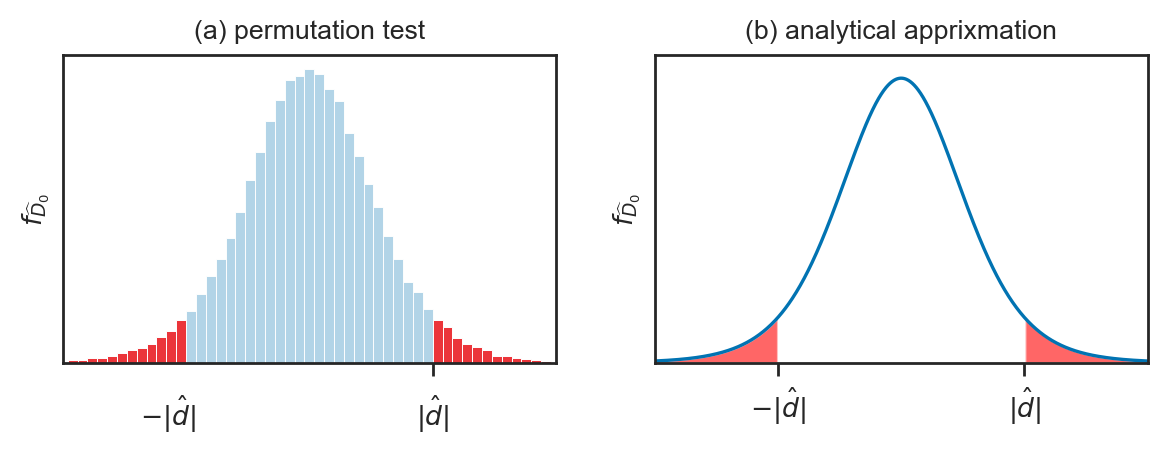

In [7]:
from ministats.book.figures import plot_panel_pvalue_D0_hist_and_dist

fig = plot_panel_pvalue_D0_hist_and_dist();

### Simulation examples

## 3.5.1 Difference between means estimator

We'll now discuss an estimators that is specific for the comparison of the two groups.

  - estimator: $\hat{d} = \DMeans(\mathbf{x}_A, \mathbf{x}_B) = \Mean(\mathbf{x}_A) - \Mean(\mathbf{x}_B) = \overline{\mathbf{x}}_A - \overline{\mathbf{x}}_B$
  - gives an estimate for the difference between population means: $\Delta =  \mu_A - \mu_B$

In [8]:
def dmeans(xsample, ysample):
    """
    Compute the difference between group means of the samples.
    """
    dhat = np.mean(xsample) - np.mean(ysample)
    return dhat

### Example N

In [9]:
# Two populations X ~ N(120,13) and Y ~ N(100,17)
from scipy.stats import norm
muX, muY = 120, 100
sigmaX, sigmaY = 13, 17
rvX = norm(muX, sigmaX)
rvY = norm(muY, sigmaY)

In [10]:
# Generate a sample of n=12 from rvX
n = 12
np.random.seed(49)
xsample = rvX.rvs(n)
xsample.round(2)

array([106.44, 109.33, 128.65, 143.69, 101.26, 123.04, 124.42, 123.01,
       119.87, 143.45, 137.78, 116.6 ])

In [11]:
# Generate a sample of m=15 from rvY
m = 15
np.random.seed(53)
ysample = rvY.rvs(m)
ysample.round(2)

array([103.5 , 119.83,  64.77,  89.24, 116.95, 140.71,  90.8 , 112.8 ,
        63.44,  94.81,  93.17,  89.6 ,  97.9 ,  91.02, 115.49])

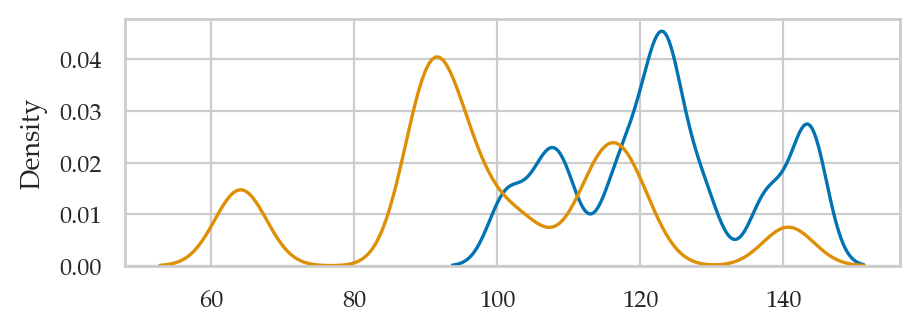

In [12]:
# DEBUGGING
bins = range(80,140,5)
# sns.histplot(xsample, bins=bins, alpha=0.3)
# sns.histplot(ysample, bins=bins, alpha=0.3)
sns.kdeplot(xsample, bw_adjust=0.3)
sns.kdeplot(ysample, bw_adjust=0.3);

In [13]:
# DEBUGGING
np.mean(xsample), np.std(xsample,ddof=1), np.mean(ysample), np.std(ysample,ddof=1)

(123.12782102038774, 13.761594639978442, 98.93506558107863, 20.322124432018075)

Compute the difference between sample means by calling `dmeans`.

In [14]:
dmeans(xsample, ysample)

24.19275543930911

### Example 3: comparison of electricity prices

Let's compute the difference between means of the East and West electricity prices.

In [15]:
eprices = pd.read_csv("datasets/eprices.csv")
# eprices

In [16]:
epricesW = eprices[eprices["loc"]=="West"]
pricesW = epricesW["price"]
pricesW

9     11.8
10    10.0
11    11.0
12     8.6
13     8.3
14     9.4
15     8.0
16     6.8
17     8.5
Name: price, dtype: float64

In [17]:
np.mean(pricesW)

9.155555555555557

In [18]:
np.var(pricesW)

2.1691358024691367

In [19]:
epricesE = eprices[eprices["loc"]=="East"]
pricesE = epricesE["price"]
pricesE

0    7.7
1    5.9
2    7.0
3    4.8
4    6.3
5    6.3
6    5.5
7    5.4
8    6.5
Name: price, dtype: float64

In [20]:
np.mean(pricesE)

6.155555555555556

In [21]:
np.var(pricesE)

0.6846913580246915

Let's calculate the mean of the prices in the East and the West:

In [22]:
np.mean(pricesW), np.mean(pricesE)

(9.155555555555557, 6.155555555555556)

To calculate the difference between means,
we can simply subtract these two numbers $\hat{d} = \overline{\mathbf{x}}_W - \overline{\mathbf{x}}_E$,
or simply call the function `dmeans`
which computes the estimate $\hat{d} = \textbf{DMeans}(\tt{pricesW}, \tt{pricesE})$.

In [23]:
dmeans(pricesW, pricesE)

3.000000000000001

According to this estimate,
the average price Rob can expect in the East end is three cents cheaper,
on average,
as compared to the average electricity price in the West.


### Sampling distribution of the difference between means

We assume the two groups are normally distributed random variables $X$ and $Y$:

$$ 
X \sim \mathcal{N}\!\left(\mu_X, \sigma_X \right)
\qquad
\textrm{and}
\qquad
Y \sim \mathcal{N}\!\left(\mu_Y, \sigma_Y \right).
$$

Definitions:

- $\mathbf{x} = (x_1, x_2, \ldots, x_{n})$=`xsample`: a sample of size $n$ from $X$
- $\mathbf{y} = (y_1, y_2, \ldots, y_{m})$=`ysample`: a sample of size $m$ from $Y$.
- $\overline{\mathbf{x}} = \Mean(\mathbf{x})$: the observed mean in the first group
- $\overline{\mathbf{y}} = \Mean(\mathbf{y})$: the observed mean in the second group
- $s_{\mathbf{x}}^2 = \Var(\mathbf{x})$: the sample variance from the first group
- $s_{\mathbf{y}}^2 = \Var(\mathbf{y})$: the sample variance from the second group
- $\hat{d} = \DMeans(\mathbf{x}, \mathbf{y}) = \overline{\mathbf{x}} - \overline{\mathbf{y}}$:
  the difference between means estimate,
  which is an estimate of the true different between
  population means $\Delta = \mu_X - \mu_Y$.

The sampling distribution of the estimator `dmeans` is defined as:

$$
  \hat{D}
   = \texttt{dmeans}(\mathbf{X}, \mathbf{Y})
   = \overline{\mathbf{X}} - \overline{\mathbf{Y}},
$$

where $\mathbf{X} = (X_1, X_2, \ldots, X_{n})$
and $\mathbf{Y} = (Y_1, Y_2, \ldots, Y_{m})$
are random samples.

<!--
If we know the population distributions for the two groups $X$ and $Y$,
we can obtain the sampling distribution
by repeatedly generating samples `xsample` and `ysample` from the two distributions,
and computing `dmeans` on the random samples. -->

### Sampling distribution for known populations

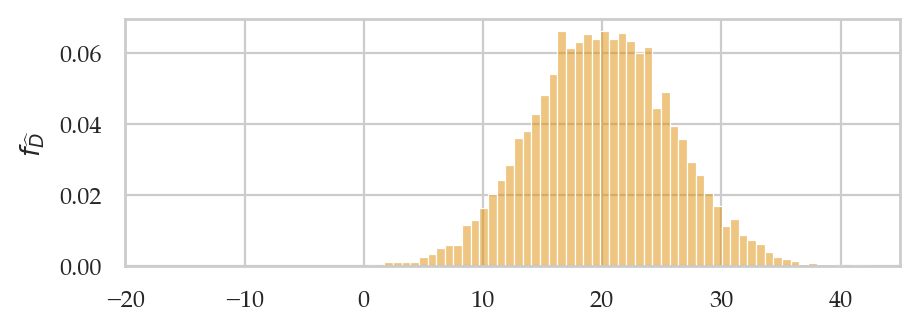

In [24]:
np.random.seed(42)

# Sample sizes
n, m = 12, 15

# Simulate 10K random samples from `rvX` and `rvY`
# and compute the difference between their means.
dhats = []
for j in range(10000):
    xs = rvX.rvs(n)
    ys = rvY.rvs(m)
    dhat = dmeans(xs, ys)
    dhats.append(dhat)

# Plot a histogram of the sampling distribution
ax = sns.histplot(dhats, stat="density", color="C1", alpha=0.5)
ax.set_xlim(-20,45)
ax.set_ylabel("$f_{\\widehat{D}}$");

In [25]:
np.std(dhats)

5.807648161384639

### Analytical formula for the sampling distribution

Let's now use probability theory to build a theoretical model for the sampling distribution of the difference-between-means estimator `dmeans`.

- The central limit theorem tells us the sample mean within the two group are

  $$
  \overline{\mathbf{X}} \sim \mathcal{N}\!\left(\mu_X, \tfrac{\sigma_X}{\sqrt{n}} \right)
  \qquad \textrm{and} \qquad
  \overline{\mathbf{Y}} \sim \mathcal{N}\!\left(\mu_Y, \tfrac{\sigma_Y}{\sqrt{m}} \right).
  $$

- The rules of probability theory tells us that the [difference of two normal random variables](https://en.wikipedia.org/wiki/Sum_of_normally_distributed_random_variables#Independent_random_variables) requires subtracting their means and adding their variance, so we get:
  $$
  \hat{D}
    \sim
    \mathcal{N}\!\left(
        \mu_X - \mu_Y, \;
        \stderr{\hat{D}}
    \right),
  $$
  
  where the standard error of the estimator $\hat{D}$ is:

  $$ 
    \stderr{\hat{D}} = \sqrt{ \tfrac{\sigma^2_X}{n} + \tfrac{\sigma^2_Y}{m}  }.
  $$

seD = 5.774945887192364


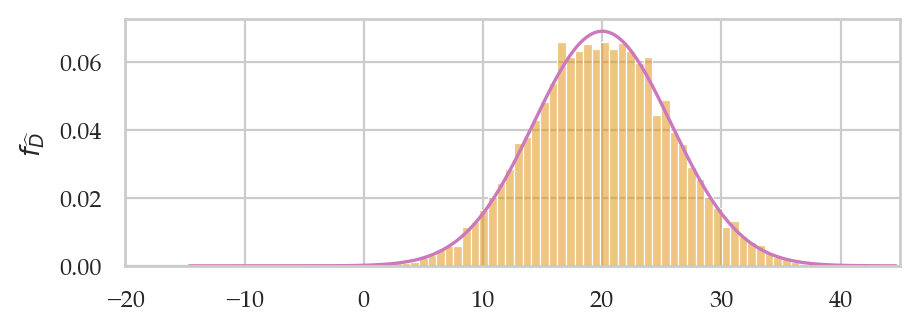

In [26]:
# Population parameters
muX, muY = 120, 100
sigmaX, sigmaY = 13, 17

# Sample sizes
n, m = 12, 15

# Standard error
seD = np.sqrt(sigmaX**2/n + sigmaY**2/m)
print("seD =", seD)

# Analytical formula for the sampling distribution
from scipy.stats import norm
rvDhatN = norm(loc=muX-muY, scale=seD)
ax = sns.histplot(dhats, stat="density", color="C1", alpha=0.5)
plot_pdf(rvDhatN, color="C4", ax=ax);
ax.set_xlim(-20,45)
ax.set_xlabel(None)
ax.set_ylabel("$f_{\\widehat{D}}$");

### Approximation using Student's $t$-distribution

Recall the plug-in principle allows us to obtain approximate statistical
formulas by replacing population parameters with estimates computed from
samples. Applying the plug-in principle to the formula
$\stderr{\hat{d}}$, we obtain a formula for the estimated standard error
of the difference between means estimator:
$$
\stderrhat{\hat{d}} = \sqrt{ \frac{s_{\mathbf{x}}^2}{n} + \frac{s_{\mathbf{y}}^2}{m} }
                = \sqrt{  \stderrhat{\overline{\mathbf{x}}}^2 + \stderrhat{\overline{\mathbf{y}}}^2 }\;.
$$

We can now build a model for the sampling distribution of the difference
between means estimator based on Student's $t$-distribution:

$$
T_{\widehat{D}}
 \;\; \sim \;\;
 \mathcal{T}(\nu_d, \; \tt{loc}\!=\!\Delta, \; \tt{scale}\!=\!\stderrhat{\hat{d}})
 \; = \;
 \stderrhat{\hat{d}} \cdot \mathcal{T}(\nu_d) \; + \; \Delta,
$$
where $\mathcal{T}(\nu_d)$ is Student's $t$-distribution with
$\nu_d$ degrees of freedom. 

The degrees of freedom of is obtained by the following formula
  $$
  \nu_d
    \;\; = \;\;
    \frac{ (\stderrhat{\overline{\mathbf{x}}}^2 + \stderrhat{\overline{\mathbf{y}}}^2)^2 }
        { \frac{\stderrhat{\overline{\mathbf{x}}}^4}{n-1}
        +   \frac{\stderrhat{\overline{\mathbf{y}}}^4}{m-1}	}\;.
  $$

Let's write a Python function that calculates the degrees of freedom parameter.

In [27]:
def calcdf(stdX, n, stdY, m):
    vX = stdX**2 / n
    vY = stdY**2 / m
    df = (vX + vY)**2 / (vX**2/(n-1) + vY**2/(m-1))
    return df

# ALT.
# from ministats import calcdf

#### Example N (continued): analytical approximation

stdX = 13.761594639978442
stdY = 20.322124432018075
sehatD = 6.5813656142388375
dfD = 24.43259380268516
dhat = 24.19275543930911


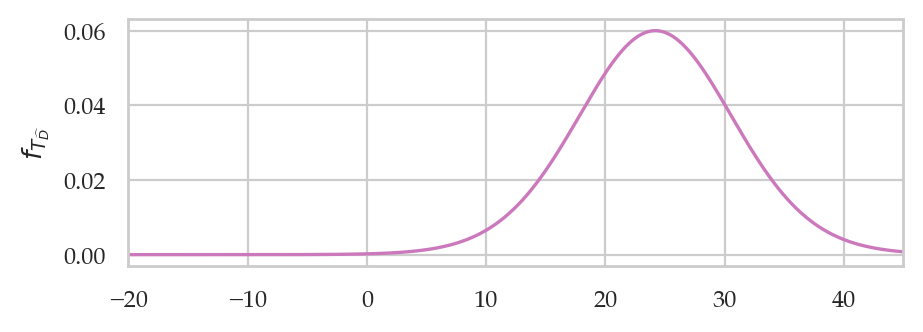

In [28]:
# Sample statistics
stdX, stdY = np.std(xsample,ddof=1), np.std(ysample,ddof=1)
n, m = len(xsample), len(ysample)
print("stdX =", stdX)
print("stdY =", stdY)

# Estimated standard error
sehatD = np.sqrt(stdX**2/n + stdY**2/m)
print("sehatD =", sehatD)

# Degrees of freedom parameter
dfD = calcdf(stdX, n, stdY, m)
print("dfD =", dfD)

# Observed difference between means
dhat = dmeans(xsample, ysample)
print("dhat =", dhat)

# Construct the analytical approximation to the sampling distribution
from scipy.stats import t as tdist
rvTDhat = tdist(df=dfD, loc=dhat, scale=sehatD)
ax = plot_pdf(rvTDhat, color="C4")
ax.set_xlim(-20,45)
ax.set_xlabel(None)
ax.set_ylabel("$f_{T_{\\widehat{D}}}$");

### Bootstrap approximation to the sampling distribution

First compute bootstrap estimates for mean in each group

In [29]:
from ministats import gen_boot_dist
xbars_boot = gen_boot_dist(xsample, estfunc=np.mean)
ybars_boot = gen_boot_dist(ysample, estfunc=np.mean)

Next we compute the difference between means from bootstrap samples

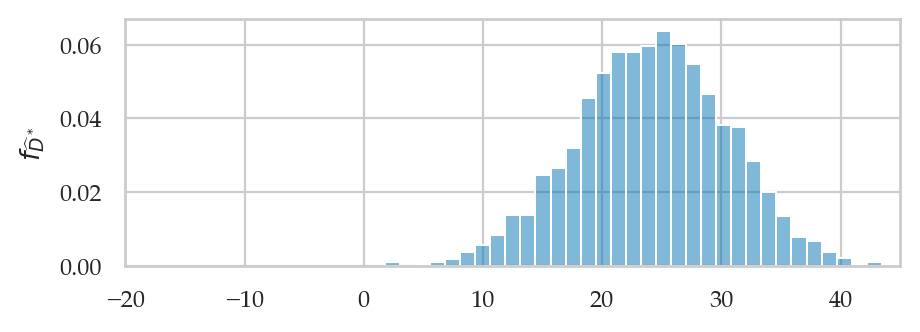

In [30]:
dhats_boot = np.subtract(xbars_boot, ybars_boot)

ax = sns.histplot(dhats_boot, stat="density", bins=35, alpha=0.5)
ax.set_xlim(-20,45)
ax.set_ylabel(r"$f_{\widehat{D}^*}$");

We can obtain the bootstrap estimate of the standard error $\stderrhat{\hat{d}}^*$
by calculating the standard deviation of the bootstrap distribution.

In [31]:
np.std(dhats_boot)

6.341245623022366

### Example 7: difference between electricity prices

Let's return to Bob's dataset of electricity prices collected from
charging stations in the East and West parts of his city. We'll assume
the prices in the two parts of the city are normally distributed and
described by the models $X_W \sim \mathcal{N}(\mu_W, \sigma_W)$ and
$X_E \sim \mathcal{N}(\mu_E, \sigma_E)$.

We have two samples $\tt{pricesW} = \mathbf{x}_W$ and
$\tt{pricesE} = \mathbf{x}_E$ from these prices

In [32]:
eprices = pd.read_csv("datasets/eprices.csv")
pricesW = eprices[eprices["loc"]=="West"]["price"]
pricesE = eprices[eprices["loc"]=="East"]["price"]

In [33]:
np.mean(pricesW),  np.mean(pricesE)

(9.155555555555557, 6.155555555555556)

In [34]:
dprice = dmeans(pricesW, pricesE)
dprice

3.000000000000001

In [35]:
# std and sample size in the East
stdW, nW = pricesW.std(), len(pricesW)

# std and sample size in the West
stdE, nE = pricesE.std(), len(pricesE)

stdW, nW, stdE, nE

(1.5621388471508475, 9, 0.8776547030454391, 9)

In [36]:
sehatDprice = np.sqrt(stdW**2/nW + stdE**2/nE)
sehatDprice

0.5972674401486562

In [37]:
dfDprice = calcdf(stdW, nW, stdE, nE)
dfDprice

12.59281702723103

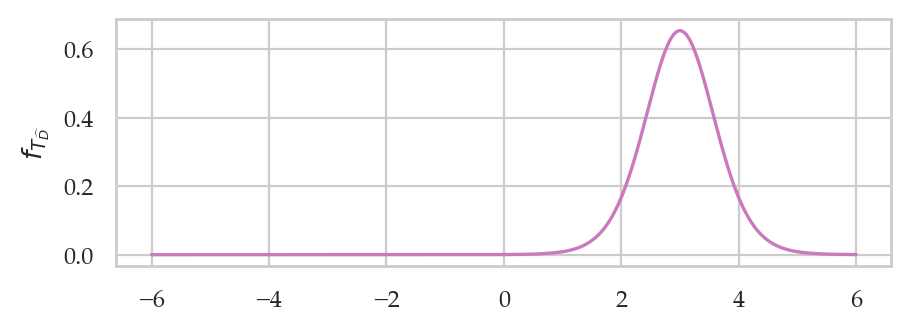

In [38]:
from scipy.stats import t as tdist
rvTDprice = tdist(df=dfDprice, loc=dprice, scale=sehatDprice)
ax = plot_pdf(rvTDprice, rv_name="D", xlims=[-6,6], color="m")
ax.set_ylabel(r"$f_{T_{\widehat{D}}}$")
ax.set_xlabel(None);

#### Bootstrapped sampling distribution of the difference between means

First compute bootstrap estimates for mean in each group

In [39]:
from ministats import gen_boot_dist
xbarsW_boot = gen_boot_dist(pricesW, estfunc=np.mean)
xbarsE_boot = gen_boot_dist(pricesE, estfunc=np.mean)

Next we compute the difference between means from bootstrap samples

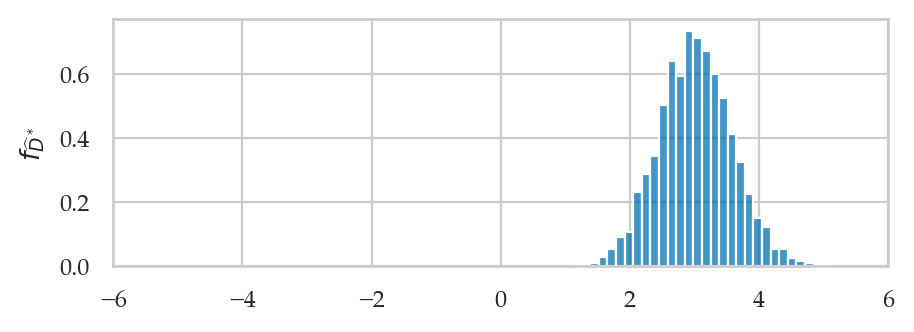

In [40]:
dprices_boot = np.subtract(xbarsW_boot, xbarsE_boot)

ax = sns.histplot(dprices_boot, stat="density", bins=30)
ax.set_xlim([-6,6])
# ax.set_xlabel("$\hat{d}$")
ax.set_ylabel(r"$f_{\widehat{D}^*}$");

We can obtain the bootstrap estimate of the standard error $\stderrhat{\hat{d}}^*$
by calculating the standard deviation of the bootstrap distribution.

In [41]:
np.std(dprices_boot)

0.5653843908460382

Note this value is very similar to the value $\stderrhat{\hat{d}}=0.598$ that we obtained
from the analytical approximation formula.
This shows that the bootstrap procedure is a viable alternative to the calculation based on analytical approximations.

## 3.5.2 Confidence interval for the difference between means

### Example 3: confidence interval for difference in electricity prices

In [42]:
eprices = pd.read_csv("datasets/eprices.csv")
pricesW = eprices[eprices["loc"]=="West"]["price"]
pricesE = eprices[eprices["loc"]=="East"]["price"]

The difference between sample means $\hat{d} = \overline{\mathbf{x}}_W - \overline{\mathbf{x}}_E$ is:

In [43]:
dprice = dmeans(pricesW, pricesE)
dprice

3.000000000000001

The estimate $\hat{d}$ will be the center of the confidence interval.

Now let's compute the parameters we need to know to calculate the standard error
of the sampling distribution.

In [44]:
# sample size and std in West and East
stdW, nW = pricesW.std(), len(pricesW)
stdE, nE = pricesE.std(), len(pricesE)
stdW, nW, stdE, nE

(1.5621388471508475, 9, 0.8776547030454391, 9)

In [45]:
# standard error
sehatDprice = np.sqrt(stdW**2/nW + stdE**2/nE)
sehatDprice

0.5972674401486562

In [46]:
# degrees of freedom
from ministats import calcdf
dfDprice = calcdf(stdW, nW, stdE, nE)
dfDprice

12.59281702723103

In [47]:
from scipy.stats import t as tdist

# calculate the quantiles of the t-distribution 
rvT = tdist(df=dfDprice)
t_05 = rvT.ppf(0.05)
t_95 = rvT.ppf(0.95)

# construct the confidence interval
[dprice + t_05*sehatDprice, dprice + t_95*sehatDprice]

[1.9396575883680864, 4.060342411631915]

#### Bootstrap confidence interval

In [48]:
# compute bootstrap estimates for mean in each group
np.random.seed(42)
xbarsW_boot = gen_boot_dist(pricesW, estfunc=np.mean)
xbarsE_boot = gen_boot_dist(pricesE, estfunc=np.mean)

# compute the difference between means of bootstrap samples
dprices_boot = np.subtract(xbarsW_boot, xbarsE_boot)

# construct the confidence interval
[np.percentile(dprices_boot,5),
 np.percentile(dprices_boot,95)]

[2.0666666666666655, 3.933888888888892]

### Reusable procedure

In [49]:
def ci_dmeans(xsample, ysample, alpha=0.1, method="a"):
    """
    Compute confidence interval for the difference between population means.
    - method="a" analytical approx. based on Student's t-dist
    - method="b" approx. based on bootstrap estimation
    """
    assert method in ["a", "b"]
    if method == "a":        # analytical approximation
        stdX, n = np.std(xsample, ddof=1), len(xsample)
        stdY, m = np.std(ysample, ddof=1), len(ysample)
        dhat = np.mean(xsample) - np.mean(ysample)
        seD = np.sqrt(stdX**2/n + stdY**2/m)
        dfD = calcdf(stdX, n, stdY, m)
        t_l = tdist(df=dfD).ppf(alpha/2)
        t_u = tdist(df=dfD).ppf(1-alpha/2)
        return [dhat + t_l*seD, dhat + t_u*seD]
    elif method == "b":          # bootstrap estimation
        xbars_boot = gen_boot_dist(xsample, np.mean)
        ybars_boot = gen_boot_dist(ysample, np.mean)
        dhats_boot = np.subtract(xbars_boot,ybars_boot)
        return [np.quantile(dhats_boot, alpha/2),
                np.quantile(dhats_boot, 1-alpha/2)]

# ALT.
# from ministats import ci_dmeans

### Empirical coverage probability evaluation

In [50]:
# Population data models X ~ N(120,13) and Y ~ N(100,17)
from scipy.stats import norm
muX, muY = 120, 100
sigmaX, sigmaY = 13, 17
rvX = norm(muX, sigmaX)
rvY = norm(muY, sigmaY)

# Sample sizes
n, m = 12, 15

# Set the random seed to a particular value to get a reproducible result
np.random.seed(42)

# Empirical coverage probability evaluation
# Empirical coverage probability evaluation
N = 100  # change to N=1000 for more accuracy
acount, bcount = 0, 0
for j in range(N):
    xs = rvX.rvs(n)
    ys = rvY.rvs(m)
    cia = ci_dmeans(xs, ys, alpha=0.1, method="a")
    if cia[0] <= muX - muY <= cia[1]:
        acount += 1
    cib = ci_dmeans(xs, ys, alpha=0.1, method="b")
    if cib[0] <= muX - muY <= cib[1]:
        bcount += 1

print("Coverage proportion of analytical approx. CIs:", acount/N)
print("Coverage proportion of bootstrap CIs:", bcount/N)

Coverage proportion of analytical approx. CIs: 0.93
Coverage proportion of bootstrap CIs: 0.92


## 3.5.3 Permutation test for comparing two populations

The **permutations test** is a computational approach for comparing two group.
The permutation test takes it's name from the action of mixing up the group-membership labels
and computing a statistic which is a way to generate samples from the null hypothesis
in situations where the null hypothesis states there is no difference between two groups.

#### Permutations

In [51]:
np.random.seed(43)
np.random.permutation([1,2,3,4,5,6,7])

array([4, 6, 3, 7, 2, 1, 5])

In [52]:
np.random.seed(45)
np.random.permutation([1,2,3,4,5,6,7])

array([6, 3, 2, 1, 5, 7, 4])

#### Resampling under the null hypothesis

In [53]:
def resample_under_H0(xsample, ysample):
    """
    Generate new samples from a random permutation of
    the values in the samples `xsample` and `xsample`.
    """
    values = np.concatenate((xsample, ysample))
    pvalues = np.random.permutation(values)
    pxsample = pvalues[0:len(xsample)]
    pysample = pvalues[len(xsample):]
    return pxsample, pysample

In [54]:
# example 1
np.random.seed(43)
resample_under_H0([1,2,3], [4,5,6,7])

(array([4, 6, 3]), array([7, 2, 1, 5]))

In [55]:
# example 2
np.random.seed(45)
resample_under_H0([1,2,3], [4,5,6,7])

(array([6, 3, 2]), array([1, 5, 7, 4]))

The function `resample_under_H0` gives us a way to generate samples from the null hypothesis.
We can then compute the value of the `dmeans` statistic for these samples. We used the assumption of "no difference" under the null hypothesis, and translated this to the "forget the labels" interpretation.

### Example 5P: electricity prices

The probability model under the alternative hypothesis
describes two populations with different parameters:

$$
   H_A: \qquad X_W = \mathcal{N}({\color{blue}{\mu_W}, \sigma_W})
   \quad \textrm{and} \quad
   X_{E} = \mathcal{N}({\color{orange}{\mu_{E}}, \sigma_{E}})
$$

Under the null hypothesis the populations have the same mean:

$$ 
   H_0: \qquad X_W = \mathcal{N}({\color{red}{\mu_0}, \sigma_W})
   \quad \textrm{and} \quad
   X_{E} = \mathcal{N}({\color{red}{\mu_0}, \sigma_{E}})
$$









In [56]:
eprices = pd.read_csv("datasets/eprices.csv")
eprices

,loc,price
0,East,7.7
1,East,5.9
2,East,7.0
3,East,4.8
4,East,6.3
5,East,6.3
6,East,5.5
7,East,5.4
8,East,6.5
9,West,11.8


In [57]:
eprices.groupby("loc")["price"].describe()

,count,mean,std,min,25%,50%,75%,max
loc,,,,,,,,
East,9.0,6.155556,0.877655,4.8,5.5,6.3,6.5,7.7
West,9.0,9.155556,1.562139,6.8,8.3,8.6,10.0,11.8


In [58]:
pricesW = eprices[eprices["loc"]=="West"]["price"]
pricesE = eprices[eprices["loc"]=="East"]["price"]

# 1. Calculate the observed difference between means
dprice = dmeans(pricesW, pricesE)
dprice

3.000000000000001

Our goal is to determine how *likely* or *unlikely* the observed value $\hat{d}=3$
is under the null hypothesis $H_0$.
This means we need to obtain the sampling distribution of $\hat{D}$ under $H_0$,
which we can do using the permutation test.

Let's look at some of the differences we can expect to observe under $H_0$.

In [59]:
#######################################################
np.random.seed(31)
# generate new samples by shuffling the labels
ppricesW, ppricesE = resample_under_H0(pricesW, pricesE)

# Compute the difference in means for the bootstrap samples
dprice0 = dmeans(ppricesW, ppricesE)
dprice0

1.6444444444444448

#### Running a permutation test

We can repeat the resampling procedure `10000` times to get the sampling distribution of $\widehat{D}_0$ under $H_0$,
as illustrated in the code procedure below.

In [60]:
np.random.seed(42)

# 2. Obtain the sampling distribution under H0
P = 10000
dprices0 = []
for i in range(0, P):
    ps1, ps2 = resample_under_H0(pricesW, pricesE)
    dprice0 = dmeans(ps1, ps2)
    dprices0.append(dprice0)

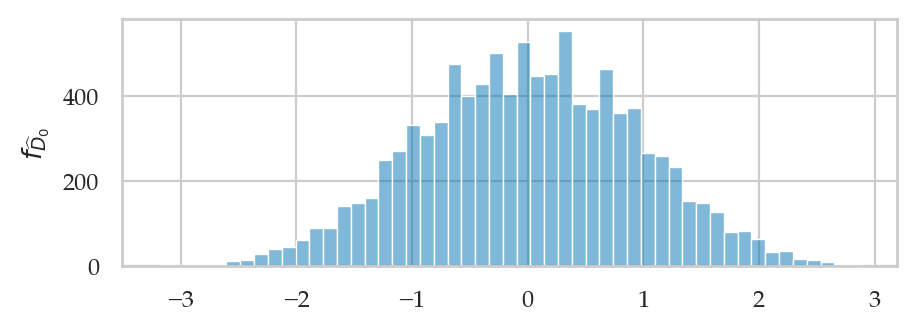

In [61]:
ax = sns.histplot(dprices0, alpha=0.5)
ax.set_ylabel(r"$f_{\widehat{D}_0}$");

Now that we have the sampling distribution $\widehat{D}_0$,
we can see where the observed value $\hat{d}= 3$ `=dprice` falls within this distribution.
The $p$-value is the probability of observing value `dprice=3` or more extreme under the null hypothesis.

In [62]:
# 3. Compute the p-value 
tails = tailvalues(dprices0, dprice, alt="two-sided")
pvalue = len(tails) / len(dprices0)
pvalue

0.0002

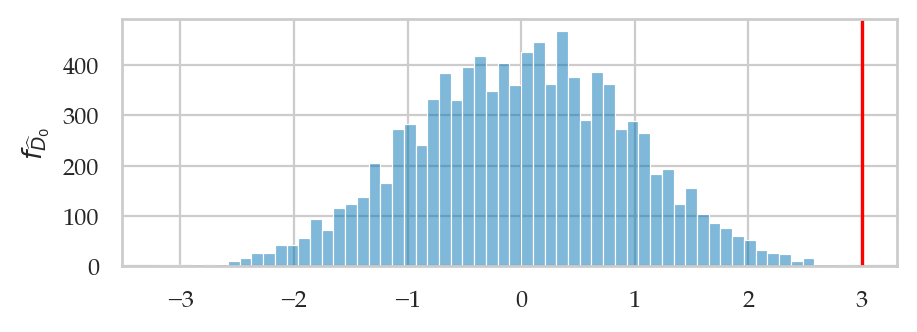

In [63]:
# plot the sampling distribution in blue
bins = nicebins(dprices0, dprice)
ax = sns.histplot(dprices0, bins=bins, alpha=0.5)

# plot red line for the observed statistic
plt.axvline(dprice, color="red")

# plot the values that are equal or more extreme in red
sns.histplot(tails, ax=ax, bins=bins, color="red")
ax.set_ylabel(r"$f_{\widehat{D}_0}$");

#### Effect size estimates

In [64]:
dprice = dmeans(pricesW, pricesE)
dprice

3.000000000000001

The bootstrap confidence interval for the effect size 
$\ci{\Delta,0.9}^*$ tells us a range of plausible values for the effect size.

In [65]:
from ministats import ci_dmeans

np.random.seed(45)
ci_dmeans(pricesW, pricesE, alpha=0.1, method="b")

[2.0777777777777775, 3.9555555555555557]

The 90% confidence interval $\ci{\Delta,0.9}^* = [2.08, 3.96]$ describes an interval of numbers
that should contain the difference between group means $\Delta$ at least 90\% of the time:

$$
    \textrm{Pr}_{\mathbf{X}}\big(\{ \Delta \in \ci{\Delta,0.9}^* \}\big) \geq 0.9.
$$


### Reusable function

In [66]:
def permutation_test_dmeans(xsample, ysample, P=10000):
    # 1. Compute the observed difference between means
    obsdhat = dmeans(xsample, ysample)

    # 2. Get sampling dist. of `dmeans` under H0
    dhats0 = []
    for i in range(0, P):
        pxs, pys = resample_under_H0(xsample, ysample)
        dhat0 = dmeans(pxs, pys)
        dhats0.append(dhat0)

    # 3. Compute the p-value
    tails = tailvalues(dhats0, obsdhat, alt="two-sided")
    pvalue = len(tails) / len(dhats0)
    return pvalue

In [67]:
np.random.seed(42)

permutation_test_dmeans(pricesW, pricesE)

0.0002

### Example NP: permutation test on the known population

In [68]:
np.random.seed(56)
permutation_test_dmeans(xsample, ysample)

0.0016

In [69]:
# # Difference between means
# dhat = dmeans(xsample, ysample)

# # Obtain the sampling distribution under H0
# np.random.seed(56)
# pdhats0 = []
# for i in range(0, 10000):
#     pxs, pys = resample_under_H0(xsample, ysample)
#     pdhat0 = dmeans(pxs, pys)
#     pdhats0.append(pdhat0)

# ax = sns.histplot(pdhats0, stat="density", bins=35, color="C1")
# plt.axvline(dhat, color="red")
# ax.set_xlim(-30,30);
# ax.set_ylabel("$f_{\\widehat{D}_0}$");

# # Compute the p-value
# tails = tailvalues(pdhats0, dhat, alt="two-sided")
# pvalue = len(tails) / len(pdhats0)
# print("p-value =", pvalue)

In [70]:
# CHECK USING scipy.stats FUNCTION
from scipy.stats import permutation_test
np.random.seed(56)
pres = permutation_test([xsample,ysample], statistic=dmeans, n_resamples=10000)
pres.pvalue

0.0021997800219978004

### Example 6P: lecture and debate curriculums

In [71]:
students = pd.read_csv("datasets/students.csv")
students.head(3)

,student_ID,background,curriculum,effort,score
0,1,arts,debate,10.96,75.0
1,2,science,lecture,8.69,75.0
2,3,arts,debate,8.60,67.0


In [72]:
students.groupby("curriculum")["score"].describe()

,count,mean,std,min,25%,50%,75%,max
curriculum,,,,,,,,
debate,8.0,76.462500,10.519633,62.9,69.55,75.55,80.925,96.2
lecture,7.0,68.142857,7.758406,57.0,63.30,70.30,73.850,75.4


In [73]:
studentsD = students[students["curriculum"]=="debate"]
studentsL = students[students["curriculum"]=="lecture"]
scoresD = studentsD["score"]
scoresL = studentsL["score"]

# observed difference between score means
dscore = dmeans(scoresD, scoresL)
dscore

8.319642857142867

Our goal is to determine how *likely* or *unlikely* this observed value $\hat{d}_s=8.32$ is under the null hypothesis $H_0$. This means we need to obtain the sampling distribution of $\hat{D}_0$ under $H_0$, which we can do using the permutation test.

In [74]:
np.random.seed(43)
pvalue = permutation_test_dmeans(scoresD, scoresL)
pvalue

0.1117

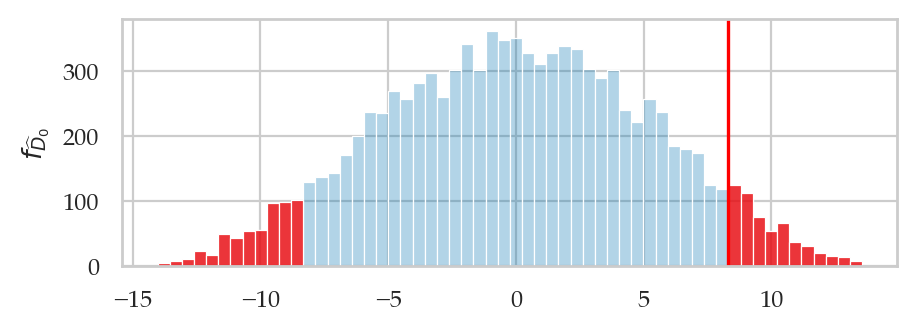

In [75]:
# generate sampling distribution under H0
np.random.seed(43)
dscores0 = []
for i in range(10000):
    ps1, ps2 = resample_under_H0(scoresD, scoresL)
    dscore0 = dmeans(ps1, ps2)
    dscores0.append(dscore0)
    
# plot the sampling distribution in blue
bins = nicebins(dscores0, dscore)
ax = sns.histplot(dscores0, bins=bins, alpha=0.3)

# plot red line for the observed statistic
plt.axvline(dscore, color="red")

# plot the values that are equal or more extreme in red
tails = tailvalues(dscores0, dscore, alt="two-sided")
# print( len(tails) / len(pdhats) )
sns.histplot(tails, bins=bins, ax=ax, color="red")
ax.set_ylabel(r"$f_{\widehat{D}_0}$");

## 3.5.4 Analytical approximation methods

We'll now look at another approach for computing the sampling distribution of the difference between means estimator, using an analytical approximations based on Student's $t$-distribution.
This is called the "two-sample $t$-test" and it is procedure most commonly taught approach in STATS 101 courses.

How likely or unlikely is the observed difference $d=3$ under the null hypothesis $H_0$?

- Analytical approximations are math models for describing the sampling distribution under $H_0$

  - Real sampling distributions: obtained by repeated sampling from $H_0$  
  - Analytical approximation: math model based on estimated parameters


- Based on this assumption we can use the theoretical model for the difference between group means
  (we assumed the two unknown populations are normally distributed),
  we can obtain a **closed form expression** for the sampling distribution of $D_0$.


- In particular, the probability model for the two groups under $H_0$ are:
  
  $$ 
       H_0: \qquad X = \mathcal{N}({\color{red}{\mu_0}}, \sigma_X)
       \quad \textrm{and} \quad
       Y = \mathcal{N}({\color{red}{\mu_0}}, \sigma_Y), \quad
  $$
  
  from which we can derive the model for $D = \overline{\mathbf{X}} - \overline{\mathbf{Y}}$:
  
  $$ 
     D_0  \sim \mathcal{N}\!\left( {\color{red}{0}}, \;  \stderr{\hat{d}} \right)
  $$
  In words, the sampling distribution of the difference between group means is
  normally distributed with mean $\Delta = 0$ and standard deviation $\stderrhat{\hat{d}}$,
  described by the formula:
  
  $$
	\stderr{\hat{d}}
		% \; = \; \sqrt{  \stderr{\overline{\mathbf{x}}}^2 + \stderr{\overline{\mathbf{y}}}^2 }
    	   = \sqrt{ \tfrac{\sigma_X^2}{n} + \tfrac{\sigma_Y^2}{m} }\;.
  $$
  The standard error of the difference between means
  depends on the variance of the two groups $\sigma_X^2$ and $\sigma_Y^2$.
  Recall we've seen this expression earlier in Section 3.1 and Section 3.2 as well.

- **Problem 1:** the population variances $\sigma_X^2$ and $\sigma_Y^2$ are unknown,
  and we only have the estimated variances $s_{\mathbf{x}}$ and $s_{\mathbf{y}}$,
  which we calculated from the samples $\mathbf{x}$ and $\mathbf{y}$.

- **Solution 1:** use **plug in estimate** and 
  We can obtain an approximation to the standard error of the difference between means estimator
  using the plug-in principle,
  which states we can use search-and-replace the population parameters
  $\sigma_X^2$ and $\sigma_Y^2$ with the estimates $s_{\mathbf{x}}$ and $s_{\mathbf{y}}$:
  
  $$
	\stderrhat{\hat{d}}
		% \; = \; \sqrt{  \stderrhat{\overline{\mathbf{x}}}^2 + \stderrhat{\overline{\mathbf{y}}}^2 }
    	   = \sqrt{ \tfrac{s_{\mathbf{x}}^2}{n} + \tfrac{s_{\mathbf{y}}^2}{m} }\;.
  $$


- **Problem 2:** the estimated standard error $\stderrhat{\hat{d}}$
  tends to underestimate the true standard error $\stderr{\hat{d}}$,
  so when we use the basic normal model
  $\mathcal{N}\!\left(\tt{loc}=0, \tt{scale}=\stderrhat{\hat{d}} \right)$
  the approximation is off (not enough weight in the tails).

- **Solution 2:** use **Student's $t$-distribution**.
  We can define a new model for the $D_0 = \overline{\mathbf{X}} - \overline{\mathbf{Y}}$
  based on Student's $t$-distribution:
  $$ 
     D_0  \sim \mathcal{T}\!\left(\tt{df}=\nu_d, \; \tt{loc}={\color{red}{0}}, \;  \tt{scale}=\stderrhat{\hat{d}} \right)
  $$
  In words, the sampling distribution of the difference between group means
  can be modeled as Student's $t$-distribution with $\nu_d$ degrees of freedom,
  centered at $0$, with scale parameter $\stderrhat{\hat{d}}$.

- The **degrees of freedom** parameter, denoted $\nu_d$ (Greek letter *nu*) in equations (`df` in code)
  determines the "weight" in the tails of the distribution.
  It is computed by a complicated formula that depends on the sample sizes $n$ and $m$,
  and the sample standard deviations $s_{\mathbf{x}}$ and $s_{\mathbf{y}}$.

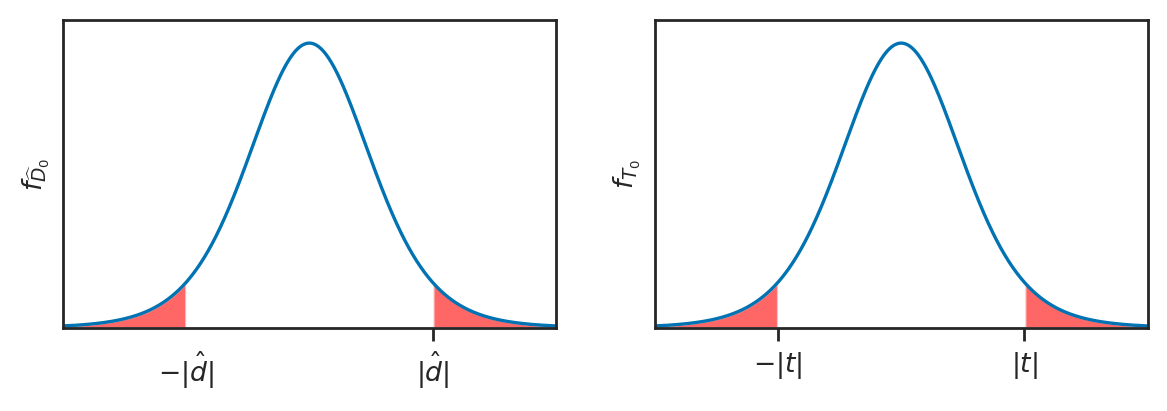

In [76]:
from ministats.book.figures import plot_panel_pvalue_D0_and_T0
plot_panel_pvalue_D0_and_T0();

### Example 5T: comparing East and West electricity prices

In [77]:
eprices = pd.read_csv("datasets/eprices.csv")
pricesW = eprices[eprices["loc"]=="West"]["price"]
pricesE = eprices[eprices["loc"]=="East"]["price"]

# Calculate the observed difference between means
dprice = dmeans(pricesW, pricesE)
dprice

3.000000000000001

#### Two-sample t-test

We'll now show the data, probability modeling, and calculation steps 
of the "two-sample $t$-test for comparing group means.
The two-sample [$t$-test](https://statkat.com/stattest.php?&t=9)
is also known as Welch's t-test.

<!-- which allows the variances in the two groups to be different. 
We'll talk about the $t$-test with pooled variances later on. 
Welch's $t$-test differs only in steps 4 through 6 as shown below:
-->

In [78]:
# Calculate the sample size and the standard deviation for each group
nW, nE = len(pricesW), len(pricesE)
stdW, stdE = np.std(pricesW,ddof=1), np.std(pricesE,ddof=1)

In [79]:
# Compute the standard error of the estimator D
seDprice = np.sqrt(stdW**2/nW + stdE**2/nE)
seDprice

0.5972674401486562

In [80]:
# Compute the value of the t-statistic
obst = (dprice - 0) / seDprice
obst

5.022875513276464

In [81]:
from ministats import calcdf
    
# Obtain the degrees of freedom from the crazy formula
dfDprice = calcdf(stdW, nW, stdE, nE)
dfDprice

12.59281702723103

In [82]:
# Calculate the p-value

from scipy.stats import t as tdist
rvT0 = tdist(df=dfDprice)
from ministats import tailprobs
pvalue = tailprobs(rvT0, obst, alt="two-sided")
pvalue

0.00025703383372176853

In [83]:
# # SKIP BECAUSE TOO SMALL TO SEE
# _, ax = calc_prob_and_plot_tails(rvT0, -obst, obst, xlims=[-6,6])
# ax.set_title(None)
# ax.set_xlabel("$t$")
# ax.set_ylabel("$f_{T_0}$");

#### Effect size estimates

In [84]:
dprice = dmeans(pricesW, pricesE)
dprice

3.000000000000001

The confidence interval for the effect size 
$\ci{\Delta,0.9}$ tells us a range of plausible values for the effect size.

In [85]:
from ministats import ci_dmeans

ci_dmeans(pricesW, pricesE, alpha=0.1, method="a")

[1.9396575883680864, 4.060342411631915]

The 90% confidence interval $\ci{\Delta,0.9} = [1.94, 4.06]$ describes an interval of numbers
that should contain the difference between group means $\Delta$ at least 90\% of the time:

$$
    \textrm{Pr}_{\mathbf{X}}\big(\{ \Delta \in \ci{\Delta,0.9} \}\big) \geq 0.9.
$$


### Reusable procedure for two-sample $t$-test

In [86]:
def ttest_dmeans(xsample, ysample):
    # Calculate the observed difference between means
    obsdhat = np.mean(xsample) - np.mean(ysample)

    # Calculate the sample sizes and the stds
    n, m = len(xsample), len(ysample)
    sx, sy = np.std(xsample,ddof=1), np.std(ysample,ddof=1)

    # Calculate the standard error, the degrees of
    # freedom, the null model, and the t-statistic
    seD = np.sqrt(sx**2/n + sy**2/m)
    dfD = calcdf(sx, n, sy, m)
    obst = (obsdhat - 0) / seD

    # Calculate the p-value from the t-distribution
    rvT0 = tdist(df=dfD)
    pvalue = tailprobs(rvT0, obst, alt="two-sided")
    return pvalue

Verify we get the same $p$-value
when using the standard error formula.

In [87]:
ttest_dmeans(pricesW, pricesE)

0.00025703383372176853

### Example NT: two-stable test with known populations

In [88]:
ttest_dmeans(xsample, ysample)

0.0011643603109388243

obst = 3.6759476463316196
p-value = 0.0011643603109388243


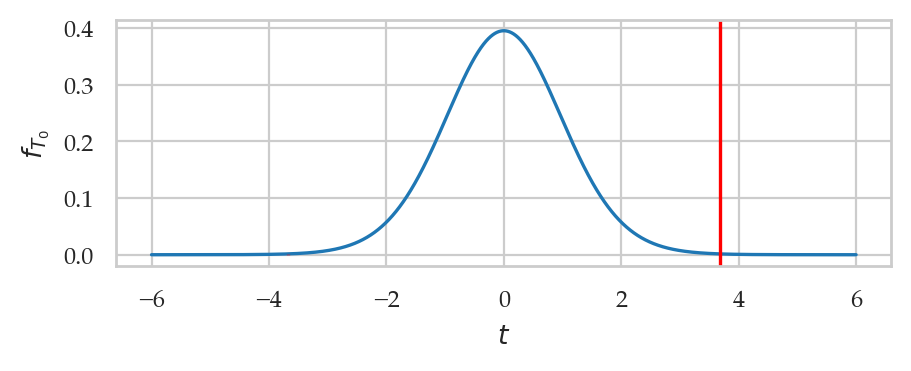

In [89]:
# DETAILS OF THE T-TEST ANALYSIS
dhat = dmeans(xsample, ysample)
stdX, stdY = np.std(xsample,ddof=1), np.std(ysample,ddof=1)
n, m = len(xsample), len(ysample)
sehatD = np.sqrt(stdX**2/n + stdY**2/m)
obst = (dhat - 0) / sehatD
print("obst =", obst)

from ministats import calcdf
dfD = calcdf(stdX, n, stdY, m)
rvT0 = tdist(df=dfD)
pvalue = tailprobs(rvT0, obst, alt="two-sided")
print("p-value =", pvalue)

from ministats import calc_prob_and_plot_tails
_, ax = calc_prob_and_plot_tails(rvT0, -obst, obst, xlims=[-6,6])
ax.set_title(None)
ax.set_xlabel("$t$")
ax.set_ylabel("$f_{T_0}$")
plt.axvline(obst, color="red");

### Example 6T: comparing rural and urban sleep scores

In [90]:
students = pd.read_csv("datasets/students.csv")
scoresD = students[students["curriculum"]=="debate"]["score"]
scoresL = students[students["curriculum"]=="lecture"]["score"]

# Observed difference between mean scores
dscores = dmeans(scoresD, scoresL)
dscores

8.319642857142867

In [91]:
ttest_dmeans(scoresD, scoresL)

0.10307495448387399

In [92]:
# T-TEST ANALYSIS
nD, nL = len(scoresD), len(scoresL)
stdD, stdL = np.std(scoresD,ddof=1), np.std(scoresL,ddof=1)
sehatDscore = np.sqrt(stdD**2/nD + stdL**2/nL)

obstDL = (dscores - 0) / sehatDscore

from ministats import calcdf
dfDscore = calcdf(stdD, nD, stdL, nL)
rvT0DL = tdist(df=dfDscore)
pvalueDL = tailprobs(rvT0DL, obstDL, alt="two-sided")
pvalueDL

0.10307495448387399

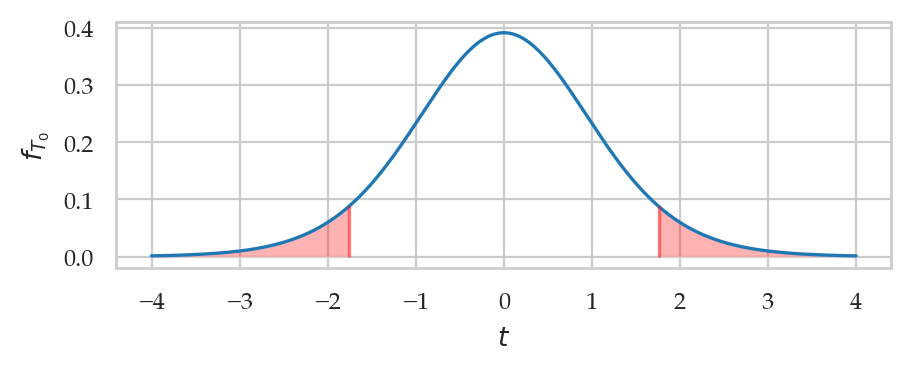

In [93]:
from ministats import calc_prob_and_plot_tails
_, ax = calc_prob_and_plot_tails(rvT0DL, -obstDL, obstDL, xlims=[-4,4])
ax.set_title(None)
ax.set_xlabel("$t$")
ax.set_ylabel("$f_{T_0}$");

## Alternative calculation methods

### Two-sample $t$-test using pooled variance
#### Pooled variance formulas


<!--

There are two common ways to obtain an approximation for $\sigma^2_D$:
  - Unpooled variance: $\sigma^2_D \approx s^2_u = \tfrac{s^2_S}{n_S} + \tfrac{s^2_{NS}}{n_{NS}}$
    (follows from the general rule of probability theory)
  - Pooled variance: $\sigma^2_D \approx s^2_p =  \frac{(n_S-1)s_S^2 \; + \; (n_{NS}-1)s_{NS}^2}{n_S + n_{NS} - 2}$
    (takes advantage of assumption that both samples come from the same population under $H_0$)
--> 

#### Example 5T revisited with pooled variance

In [94]:
# TODO make self contained

In [95]:
# Compute the pooled variance and standard error of estimator D
varp = ((nW-1)*stdW**2 + (nE-1)*stdE**2) / (nW + nE - 2)
stdp = np.sqrt(varp)
sehatDp = stdp * np.sqrt(1/nW + 1/nE)
sehatDp

0.5972674401486562

In [96]:
# Compute the value of the t-statistic
obstp = (dprice - 0) / sehatDp
obstp

5.022875513276464

In [97]:
# Obtain the degrees of freedom
dfDp = nW + nE - 2
dfDp

16

In [98]:
from scipy.stats import t as tdist
from ministats import tailprobs

# Calculate the p-value
rvT0p = tdist(df=dfDp)
pvaluep = tailprobs(rvT0p, obstp, alt="two-sided")
pvaluep

0.00012497067987674888

#### Bootstrap confidence interval using `scipy`

In [99]:
# two-sample test `scipy.stats`
from scipy.stats import bootstrap

np.random.seed(42)
res = bootstrap([pricesW, pricesE], statistic=dmeans,
                confidence_level=0.9, n_resamples=5000,
                vectorized=False, method="percentile")
[res.confidence_interval.low,
 res.confidence_interval.high]

[2.0666666666666655, 3.933888888888892]

Note the result is the same as ...

#### Confidence intervals using `statsmodels`

In [100]:
import statsmodels.stats.api as sms

statsW = sms.DescrStatsW(pricesW)
statsE = sms.DescrStatsW(pricesE)
cm = sms.CompareMeans(statsW, statsE)
cm.tconfint_diff(alpha=0.1, usevar="unequal")

(1.9396575883680873, 4.060342411631915)

Note the result is the same as ...

In the above code example, the functions `sms.DescrStatsW` compute the descriptive statistics
for the two samples, then `sms.CompareMeans` performs the comparison of means statistical analysis.
We call the method `tconfint_diff` to extract the 90\% confidence interval from the result.

As you can see,
the numbers we obtain from the `statsmodels`
is exactly the same as the confidence interval we computed manually.

#### Confidence interval using `pinguouin`

In [101]:
import pingouin as pg

res = pg.ttest(pricesW, pricesE, confidence=0.9, correction=True)
res["CI90"].values[0]

array([1.93965759, 4.06034241])

### Using `scipy.stats.permutation_test` for permutation test

You can use the SciPy implementation of permutation test,
by calling the function `permutation_test` to perform a permutation test, then obtain the $p$-value.

In [102]:
from scipy.stats import permutation_test

np.random.seed(42)

res3 = permutation_test([pricesW,pricesE], statistic=dmeans, n_resamples=10000)
res3.pvalue

0.00019998000199980003

Note the $p$-value we obtained form the two methods may be different.
This can happen when using the permutations test,
because we use randomness as part of the calculation.

### Using `scipy.stats.ttest_ind` for two-sample $t$-tests

Alternatively,
we can use `scipy.stats.ttest_ind` to obtain the $p$-value.

Use `equal_var=False` to obtain the Welsh value.

In [103]:
# ALT. compute using existing function in `scipy.stats`
from scipy.stats import ttest_ind
res1 = ttest_ind(pricesW, pricesE, equal_var=False)
res1.pvalue

0.0002570338337217615

Use `equal_var=True` to obtain the pooled variance value.

In [104]:
# ALT. compute using existing function in `scipy.stats`
from scipy.stats import ttest_ind
res2 = ttest_ind(pricesW, pricesE, equal_var=True)
res2.pvalue

0.00012497067987678515

### Using `statsmodels` for two-sample $t$-tests

In [105]:
import statsmodels.stats.api as sms

statsW = sms.DescrStatsW(pricesW)
statsE = sms.DescrStatsW(pricesE)
cm = sms.CompareMeans(statsW, statsE)

# Welch's t-test
cm.ttest_ind(alternative="two-sided", usevar="unequal")

(5.022875513276465, 0.0002570338337217606, 12.592817027231032)

In [106]:
# T-test with pooled variance
cm.ttest_ind(alternative="two-sided", usevar="pooled")

(5.022875513276465, 0.00012497067987678515, 16.0)

## Explanations

### Statistical modelling assumptions


- INDEP:
- NORMAL:
- LARGEn:
- EQVAR:

### Standardized effect size

It is sometimes useful to report the effect size using a "standardized" measure for effect sizes.

Cohen's $d$ is one such measure, and it is defined as the difference between two means divided by the pooled standard deviation.

$$
  d = \frac{\overline{\mathbf{x}} - \overline{\mathbf{y}} }{ s_{p} }.
$$
where the pooled variance is defined as
$s_{p}^2 = [(n -1)s_{\mathbf{x}}^2 + (m -1)s_{\mathbf{y}}^2]/(n + m -2)$.


In [107]:
def cohend2(sample1, sample2):
    """
    Cohen's d measure of effect size for two independent samples.
    """
    n1, n2 = len(sample1), len(sample2)
    mean1, mean2 = np.mean(sample1), np.mean(sample2)
    var1, var2 = np.var(sample1,ddof=1), np.var(sample2,ddof=1)
    # Calculate the pooled variance and standard deviation
    var_pooled = ((n1-1)*var1+(n2-1)*var2) / (n1+n2-2)
    std_pooled = np.sqrt(var_pooled)
    d = (mean1 - mean2) / std_pooled
    return d

We interpret the value of Cohen's $d$ using the [reference table](https://en.wikipedia.org/wiki/Effect_size#Cohen's_d) of values:

| Cohen's d   | Effect size |
| ----------- | ----------- |
| 0.01        | very small  |
| 0.20        | small       |
| 0.50        | medium      |
| 0.80        | large       |


Effect size for mean deviation of kombucha Batch 04 from expected value $\mu_K=1000$.

In [108]:
cohend2(pricesW, pricesE)

2.367806224329099

## Discussion
### Comparison to resampling methods

## Exercises

See notebook [sec35_comparing_two_groups.ipynb](../exercises/sec35_comparing_two_groups.ipynb).

## Links

* [Permutation Methods: A Basis for Exact Inference](https://projecteuclid.org/journals/statistical-science/volume-19/issue-4/Permutation-Methods-A-Basis-for-Exact-Inference/10.1214/088342304000000396.full) by Michael D. Ernst

* Nice animation https://commons.wikimedia.org/wiki/File:Permutation_test_example_animation.gif  
  via https://en.wikipedia.org/wiki/Permutation_test

## CUT MATERIAL

### Example sampling dist using pivotal transformation

Recall the sampling distribution of the difference between means `rvTDprice`.
Here are some examples of equivalent calculations using standard $t$-distribution.

In [109]:
dfD = calcdf(stdW, nW, stdE, nE)
rvT = tdist(df=dfD)

In [110]:
rvTDprice.ppf(0.95), rvTDprice.ppf(0.95)*seD + dhat

(4.060342411631915, 47.641013149955555)

In [111]:
rvTDprice.cdf(4), rvTDprice.cdf( (4-dhat)/seD )

(0.9406438830093703, 4.556607350244164e-08)

## NEW STUFF (TODO: merge with above)

TODO: distribute the following plots into appropriate subsections

#### Bootstrap approximation

In [112]:
from ministats import ci_dmeans
ci_dmeans(xsample,ysample, method="b")

[13.540768158298691, 34.5974768136927]

#### Analytical approximation

In [113]:
ci_dmeans(xsample,ysample, method="a")

[12.940807861945025, 35.44470301667319]

### Simulated sampling distribution under null

In [114]:
# CUT BECAUSE CONFUSING SINCE NEEDS A DIFFERENT, HYPOTHETICAL DATA MODEL
# # Two populations with the same mean X ~ N(100,13) and Y ~ N(100,17)
# from scipy.stats import norm
# muX0, muY0 = 100, 100
# sigmaX0, sigmaY0 = 13, 17
# rvX0 = norm(muX0, sigmaX0)
# rvY0 = norm(muY0, sigmaY0)

# # Two samples of sizes n=12 and m=15
# np.random.seed(55)
# n = 12
# x0sample = rvX0.rvs(n)

# np.random.seed(56)
# m = 15
# y0sample = rvY0.rvs(m)

In [115]:
# N = 10000
# dhats0 = []
# for j in range(0,N):
#     x0sample = rvX0.rvs(n)
#     y0sample = rvY0.rvs(m)
#     dhat0 = dmeans(x0sample, y0sample)
#     dhats0.append(dhat0)

# sns.histplot(dhats0, alpha=0.5);

#### Sampling distribution from the permutation test

0.0011998800119988001

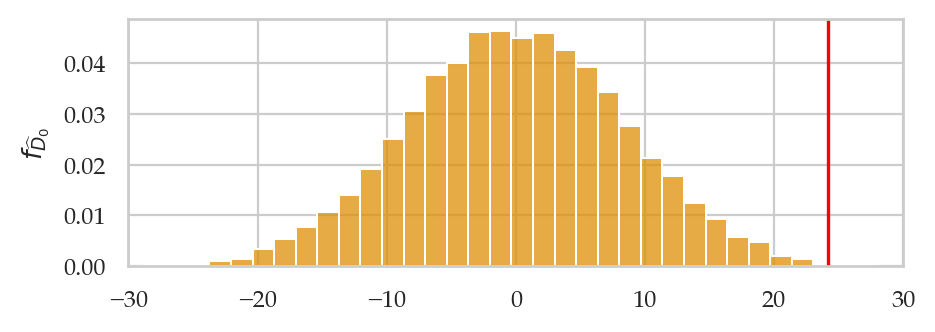

In [116]:
from scipy.stats import permutation_test

dhat = dmeans(xsample, ysample)

np.random.seed(42)
pres = permutation_test([xsample,ysample], statistic=dmeans, n_resamples=10000)
ax = sns.histplot(pres.null_distribution, stat="density", bins=35, color="C1")
plt.axvline(dhat, color="red")
ax.set_xlim(-30,30);
ax.set_ylabel("$f_{\\widehat{D}_0}$");
pres.pvalue

In [117]:
# np.random.seed(45)
from ministats import permutation_test_dmeans
permutation_test_dmeans(xsample, ysample)

0.0022

#### Sampling distribution from analytical approximation

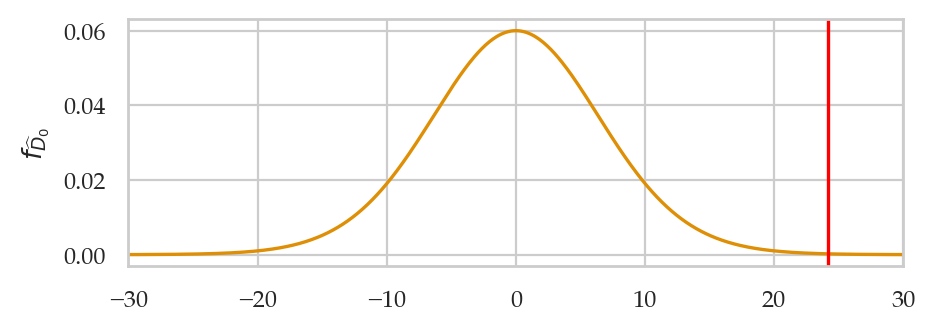

In [118]:
# Sample statistics
dhat = dmeans(xsample, ysample)
stdX, stdY = np.std(xsample,ddof=1), np.std(ysample,ddof=1)

# Estimated standard error
sehatD = np.sqrt(stdX**2/n + stdY**2/m)

# Degrees of freedom, the null model, and the t-statistic
dfD = calcdf(stdX, n, stdY, m)

# Calculate the p-value from the t-distribution
rvDhat = tdist(df=dfD, loc=0, scale=sehatD)
ax = plot_pdf(rvDhat, color="C1")
plt.axvline(dhat, color="red")
ax.set_xlim(-30, 30);
ax.set_xlabel("")
ax.set_ylabel("$f_{\\widehat{D}_0}$");

In [119]:
from ministats import ttest_dmeans
ttest_dmeans(xsample, ysample)

0.0011643603109388243